In [1]:
import pandas as pd
from typing import List
import rpy2
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import cellseg_benchmark._constants as _constants
from cellseg_benchmark.metrics import clean_method_name

/home/ubuntu/miniforge3/envs/analysis/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/ubuntu/miniforge3/envs/analysis/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext rpy2.ipython

2026-11-13 08:21:16,190 [INFO]: cffi mode is CFFI_MODE.ANY
2026-11-13 08:21:16,192 [INFO]: R home found: /home/ubuntu/miniforge3/envs/analysis/lib/R
2026-11-13 08:21:16,412 [INFO]: R library path: 
2026-11-13 08:21:16,415 [INFO]: LD_LIBRARY_PATH: 
2026-11-13 08:21:16,428 [INFO]: Default options to initialize R: rpy2, --quiet, --no-save
2026-11-13 08:21:16,630 [INFO]: Environment variable "PWD" redefined by R and overriding existing variable. Current: "/", R: "/dss/dsshome1/00/ra87rib"
2026-11-13 08:21:16,839 [INFO]: R is already initialized. No need to initialize.


In [3]:
!mamba install -y -q -p {sys.prefix} -c conda-forge r-svglite r-dplyr r-tibble r-ggplot2 r-rcolorbrewer r-ggforce r-jsonlite r-sysfonts r-showtext

warning  libmamba Cache file "/home/ubuntu/miniforge3/pkgs/cache/497deca9.json" was modified by another program
warning  libmamba Cache file "/home/ubuntu/miniforge3/pkgs/cache/09cdf8bf.json" was modified by another program
Preparing transaction: ...working... done
Verifying transaction: ...working... done
Executing transaction: ...working... done


In [4]:
%%R
if (!requireNamespace("funkyheatmap", quietly = TRUE))
  install.packages("funkyheatmap", repos = "https://cloud.r-project.org")

* installing *source* package ‘assertthat’ ...
** this is package ‘assertthat’ version ‘0.2.1’
** package ‘assertthat’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (assertthat)
* installing *source* package ‘funkyheatmap’ ...
** this is package ‘funkyheatmap’ version ‘0.5.2’
** package ‘funkyheatmap’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
*** copying figures
** building package indices
** installing vignettes
** testing if installed package can be 

also installing the dependency ‘assertthat’

trying URL 'https://cloud.r-project.org/src/contrib/assertthat_0.2.1.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/funkyheatmap_0.5.2.tar.gz'

The downloaded source packages are in
	‘/tmp/Rtmp2EtpDB/downloaded_packages’
Updating HTML index of packages in '.Library'
Making 'packages.html' ... done


In [5]:
main_dir = Path("/dss/dsshome1/00/ra87rib/cellseg-benchmark")

In [29]:
cohorts = ["aging"]
exclude = ["Negative_Control_Visium", "Watershed_Merlin"]  # methods left out of the tables
output_folders = ["general_stats", "assigned_transcripts", "cell_type_metrics", "marker_gene_metrics", "ficture", "cell_density"]

dfs_by = {c: {csv.stem: pd.read_csv(csv, index_col=0)
              for name in output_folders
              for csv in (main_dir / "metrics" / c / name).glob("*.csv")# if "vascular" not in csv.name
             }
          for c in cohorts}
{c: len(d) for c, d in dfs_by.items()}

{'aging': 16}

In [17]:
def compute_gen_stats_subsets(
    gen_stats: pd.DataFrame,
    cell_types: list | None = None,
    celltype_name: str = "cell_type_revised",
):
    if cell_types is None:
        cell_types = gen_stats[celltype_name].unique().tolist()

    df = (
        gen_stats.loc[gen_stats[celltype_name].isin(cell_types)]
        .drop(columns=celltype_name)
        .copy()
    )

    grouped = df.groupby(["method", "sample"], observed=True)

    counts = grouped["n_cells"].sum().rename("n_cells")
    means = grouped[
        df.select_dtypes(include="number").columns.difference(["n_cells"])
    ].mean()

    return pd.concat([means, counts], axis=1).reset_index()


def compute_f1_subsets(
    ficture: pd.DataFrame,
    cell_types: list | None = None,
    celltype_name: str = "cell_type",
    f1_col: str = "f1",
):
    df = ficture.loc[ficture["sample"] != "all_samples"].copy()

    if cell_types is None:
        cell_types = df[celltype_name].unique().tolist()

    df = df.loc[
        df[celltype_name].isin(cell_types),
        ["method", "sample", celltype_name, "tp", "fp", "fn", f1_col],
    ]

    aggregations = {
        "tp": "sum",
        "fp": "sum",
        "fn": "sum",
        f1_col: "mean",
    }

    res = (
        df.groupby(
            ["method", "sample", celltype_name],
            observed=True,
        )
        .agg(aggregations)
        .groupby(["method", "sample"], observed=True)
        .agg(aggregations)
        .rename(columns={f1_col: "f1_macro"})
    )

    res["precision"] = res["tp"] / (res["tp"] + res["fp"])
    res["recall"] = res["tp"] / (res["tp"] + res["fn"])
    res["f1_micro"] = (
        2 * res["tp"]
        / (2 * res["tp"] + res["fp"] + res["fn"])
    )

    return res.reset_index()


def per_method(df, cols, key="method"):
    return (
        df.query("sample != 'all'")
        .groupby(key, observed=True)[cols]
        .mean()
    )
def _build_benchmark_table_subset(
    dfs,
    exclude=(),
    cell_types=None,
    *,
    categories,
    methods_3d=None,
    MECR_suffix="all",
    clustering_key=None,
):
    """Build a subset benchmark table, optionally including silhouette."""
    if methods_3d is None:
        methods_3d = _constants.methods_3D

    descriptive = [
        "volume_final",
        "elongation",
        "intensities_PolyT",
        "intensities_DAPI",
    ]
    scored_metrics = [
        "MECR_adj",
        "marker_f1",
        "ficture_f1_score",
        "Ovrlpy_stats_mean_integrity",
    ]
    if clustering_key is not None:
        scored_metrics.insert(0, "silhouette_score")

    metrics = scored_metrics + descriptive

    # General statistics and transcript counts.
    gs = compute_gen_stats_subsets(
        dfs["general_stats"],
        cell_types=cell_types,
    )

    counts = (
        dfs["assigned_transcript_counts"]
        .groupby(["sample", "method"], observed=True)[
            ["assigned_count_qced", "total_count"]
        ]
        .sum()
    )
    counts["pct_assigned_qced"] = (
        counts["assigned_count_qced"] / counts["total_count"]
    )
    counts["tpc"] = (
        counts["assigned_count_qced"]
        / gs.set_index(["sample", "method"])["n_cells"]
    )

    # Aggregate F1 scores using the existing two-stage macro calculation.
    def mean_f1(key, name, f1_col="f1"):
        return (
            compute_f1_subsets(
                dfs[key],
                cell_types=cell_types,
                f1_col=f1_col,
            )
            .groupby("method", observed=True)["f1_macro"]
            .mean()
            .rename(name)
        )

    parts = [
        per_method(
            gs,
            descriptive + ["Ovrlpy_stats_mean_integrity", "n_cells"],
        ),
        per_method(counts, ["pct_assigned_qced", "tpc"]),
    ]

    if clustering_key is not None:
        # Preserve the original clustering aggregation:
        # do not apply per_method()'s sample filter here.
        parts.append(
            dfs[clustering_key]
            .groupby("method")[["silhouette_score"]]
            .mean()
        )

    parts.extend([
        per_method(
            dfs[f"MECR_score_{MECR_suffix}"].query("gene1 == 'all'"),
            "MECR",
        ).rename("MECR"),
        mean_f1(
            "marker_f1_score_cell_type_revised",
            "marker_f1",
            f1_col="f1_score",
        ),
        mean_f1("ficture_f1", "ficture_f1_score"),
    ])

    df = pd.concat(parts, axis=1).drop(
        index=list(exclude),
        errors="ignore",
    )

    # Fit MECR adjustment using non-control methods after exclusions.
    df["is_control"] = df.index.str.startswith("Negative_Control")
    fit_data = df.loc[
        ~df["is_control"], ["MECR", "tpc"]
    ].dropna()

    if (
        len(fit_data) < 2
        or not np.isfinite(fit_data.to_numpy()).all()
        or (fit_data["tpc"] <= 0).any()
        or fit_data["tpc"].nunique() < 2
    ):
        raise ValueError(
            "MECR adjustment requires at least two non-control methods "
            "with finite MECR, positive finite tpc, and distinct tpc values."
        )

    fit = np.polyfit(
        np.log10(fit_data["tpc"]),
        fit_data["MECR"],
        1,
    )
    valid_tpc = df["tpc"].where(
        np.isfinite(df["tpc"]) & (df["tpc"] > 0)
    )
    df["MECR_adj"] = (
        df["MECR"] - np.polyval(fit, np.log10(valid_tpc))
    )

    # Missing-value handling.
    is_3d = df.index.str.startswith(tuple(methods_3d))
    is_ficture_seg = df.index.str.startswith("Ficture_segments")

    df.loc[is_ficture_seg, "ficture_f1_score"] = np.nan
    df["na_z"] = is_3d & df["Ovrlpy_stats_mean_integrity"].isna()
    df["na_ficture"] = (
        (is_3d | is_ficture_seg) & df["ficture_f1_score"].isna()
    )

    raw = df.copy()

    # Preserve the supplied code's scaling, without MECR inversion.
    values = df[metrics]
    reference = values.loc[~df["is_control"]]
    low, high = reference.min(), reference.max()

    df[metrics] = ((values - low) / (high - low)).clip(0, 1)

    # Validate category definitions.
    if not categories:
        raise ValueError("categories must contain at least one category.")

    empty_categories = [
        name for name, cols in categories.items() if len(cols) == 0
    ]
    if empty_categories:
        raise ValueError(
            f"Categories contain no metrics: {empty_categories}"
        )

    category_metrics = {
        col for cols in categories.values() for col in cols
    }
    unavailable = category_metrics - set(metrics)
    if unavailable:
        raise ValueError(
            "These category metrics are not available among the "
            f"normalized subset metrics: {sorted(unavailable)}"
        )

    # Average within categories, then across categories.
    category_scores = pd.DataFrame(
        {
            name: df[cols].mean(axis=1)
            for name, cols in categories.items()
        },
        index=df.index,
    )
    df["total_score"] = category_scores.mean(axis=1)

    if {"clustering", "marker"}.issubset(category_scores.columns):
        df["expr_score"] = category_scores[
            ["clustering", "marker"]
        ].mean(axis=1)

    df["total_score_label"] = df["total_score"].map(
        lambda x: f" {x:.2f}"
    )
    df = (
        df.sort_values("total_score", ascending=False)
        .rename_axis("id")
        .reset_index()
    )
    df["id"] = df["id"].map(clean_method_name)

    return df, raw


def build_benchmark_table_subsets(
    dfs,
    exclude=(),
    cell_types=None,
    *,
    categories,
    methods_3d=None,
    MECR_suffix="all",
):
    """Build the subset benchmark table without silhouette."""
    return _build_benchmark_table_subset(
        dfs,
        exclude=exclude,
        cell_types=cell_types,
        categories=categories,
        methods_3d=methods_3d,
        MECR_suffix=MECR_suffix,
    )


def build_benchmark_table_vasc_subset(
    dfs,
    exclude=(),
    cell_types=None,
    *,
    categories,
    methods_3d=None,
    MECR_suffix="vascular_celltypes",
    clustering_mod="vascular_subset",
):
    """Build the vascular subset benchmark table with silhouette."""
    return _build_benchmark_table_subset(
        dfs,
        exclude=exclude,
        cell_types=cell_types,
        categories=categories,
        methods_3d=methods_3d,
        MECR_suffix=MECR_suffix,
        clustering_key=(
            f"clustering_score_adata_{clustering_mod}_cell_type_revised"
        ),
    )


In [19]:
%%R
plot_benchmark_heatmap_subset_new <- function(
  df_funky,
  out_file,
  metric_labels,
  family = "Arial",
  font_file = "/dss/dsshome1/00/ra87rib/cellseg-benchmark/misc/Arial.ttf",
  score_label = "Overall"
) {
  library(funkyheatmap)
  library(dplyr)
  library(tibble)
  library(ggplot2)
  library(RColorBrewer)

  sysfonts::font_add(
    family = family,
    regular = path.expand(font_file)
  )
  showtext::showtext_auto()
  showtext::showtext_opts(dpi = 600)
  update_geom_defaults("text", list(family = family))

  required_flags <- c("na_ficture", "na_z")
  missing_flags <- setdiff(required_flags, names(df_funky))

  if (length(missing_flags) > 0L) {
    stop(
      "Missing flag columns: ",
      paste(missing_flags, collapse = ", "),
      ". Use the updated Python benchmark-table builder."
    )
  }

  for (s in c("sep1", "sep2", "sep3")) {
    df_funky[[s]] <- ""
  }

  # Retain the subset metrics; match the global layout.
  box <- list(width = 1.08)

  col_spec <- tribble(
    ~id,                           ~group,       ~geom,       ~palette,     ~name,         ~opts,
    "id",                          "",           "text",      NA,           "",            list(width = 8.8, hjust = 0),
    "total_score",                 "overall",    "bar",       "overall",    "",            list(width = 3.2, draw_outline = FALSE),
    "sep1",                        "",           "text",      NA,           "",            list(width = 0.3),

    "MECR_adj",                    "expression", "funkyrect", "expression", "MECR",        box,
    "marker_f1",                   "expression", "funkyrect", "expression", "Marker F1",   box,

    "sep2",                        "",           "text",      NA,           "",            list(width = 0.3),

    "ficture_f1_score",            "spatial",    "funkyrect", "spatial",    "Ficture F1",  box,
    "Ovrlpy_stats_mean_integrity", "spatial",    "funkyrect", "spatial",    "Z integrity", box,

    "sep3",                        "",           "text",      NA,           "",            list(width = 0.8),

    "volume_final",                "general",    "funkyrect", "general",    "Volume",      box,
    "elongation",                  "general",    "funkyrect", "general",    "Elongation",  box,
    "intensities_PolyT",           "general",    "funkyrect", "general",    "PolyT",       box,
    "intensities_DAPI",            "general",    "funkyrect", "general",    "DAPI",        box
  )

  column_info <- col_spec %>%
    left_join(metric_labels, by = "id", suffix = c("", "_label")) %>%
    mutate(
      name = coalesce(name_label, name),
      options = opts,
      legend = FALSE
    ) %>%
    select(-name_label, -opts)

  column_groups <- tribble(
    ~group,       ~level1,               ~palette,
    "overall",    score_label,           "overall",
    "expression", "Expression",          "expression",
    "spatial",    "Spatial",             "spatial",
    "general",    "General (unscored)",  "general"
  )

  pal <- function(name, i = 2:7) {
    brewer.pal(9, name)[i]
  }

  palettes <- list(
    overall = colorRampPalette(
      c("#FFF3CF", "#FBC36A", "#E08A3C", "#C46A35")
    )(6),
    expression = pal("Purples"),
    spatial = colorRampPalette(c("#FCE4DC", "#C25B4E"))(6),
    general = pal("Greens")
  )

  legends <- list(
    list(
      title = if (score_label == "Overall") "Total score" else score_label,
      palette = "overall",
      geom = "bar",
      labels = c("0", "", "0.5", "", "1"),
      size = c(0, 0.25, 0.5, 0.75, 1),
      color = palettes$overall[c(1, 2, 4, 5, 6)]
    ),
    list(
      title = "Scaled metric",
      palette = "expression",
      geom = "funkyrect",
      labels = c("min", "", "", "", "max"),
      size = c(0.1, 0.3, 0.5, 0.75, 1),
      color = pal("Greys", c(2, 3, 5, 6, 7)),
      label_hjust = 0
    ),
    list(palette = "spatial", enabled = FALSE),
    list(palette = "general", enabled = FALSE)
  )

  g <- funky_heatmap(
    df_funky,
    column_info = column_info,
    column_groups = column_groups,
    palettes = palettes,
    legends = legends,
    scale_column = FALSE,
    position_args = position_arguments(
      row_height = 1.08,
      row_space = 0.02,
      col_space = 0.02,
      expand_xmax = 4.5,
      expand_ymin = 0,
      expand_ymax = 0.3,
      col_annot_offset = 3.6,
      col_annot_angle = 45
    )
  )

  p <- g[[1]]

  # Extract coordinates from the plot layers.
  position_fields <- c(
    "label_value", "row_id", "xmin", "xmax", "ymin", "ymax"
  )

  pos <- bind_rows(lapply(p$layers, function(layer) {
    layer_data <- layer$data

    if (!is.data.frame(layer_data)) {
      return(NULL)
    }

    layer_data %>%
      select(any_of(position_fields)) %>%
      mutate(across(everything(), as.character))
  })) %>%
    mutate(across(c(xmin, xmax, ymin, ymax), as.numeric))

  col_x <- function(id) {
    column_name <- column_info$name[match(id, column_info$id)]

    hit <- pos %>%
      filter(
        label_value == column_name,
        is.finite(xmin),
        is.finite(xmax)
      ) %>%
      slice(1)

    if (nrow(hit) == 0L) {
      stop("Could not find plot coordinates for column: ", id)
    }

    c(hit$xmin, hit$xmax)
  }

  rows <- pos %>%
    filter(
      row_id %in% df_funky$id,
      is.finite(ymin),
      is.finite(ymax)
    ) %>%
    group_by(row_id) %>%
    summarise(
      y = (min(ymin) + max(ymax)) / 2,
      .groups = "drop"
    )

  # Positions for the original missing-value flags.
  na_marks <- bind_rows(
    tibble(
      row_id = as.character(
        df_funky$id[which(df_funky$na_ficture %in% TRUE)]
      ),
      x = rep(
        mean(col_x("ficture_f1_score")),
        sum(df_funky$na_ficture %in% TRUE)
      )
    ),
    tibble(
      row_id = as.character(
        df_funky$id[which(df_funky$na_z %in% TRUE)]
      ),
      x = rep(
        mean(col_x("Ovrlpy_stats_mean_integrity")),
        sum(df_funky$na_z %in% TRUE)
      )
    )
  ) %>%
    left_join(rows, by = "row_id")

  # Match the global version's group-heading size.
  text_layers <- which(vapply(
    p$layers,
    function(layer) inherits(layer$geom, "GeomText"),
    logical(1)
  ))

  for (i in text_layers) {
    layer_data <- p$layers[[i]]$data

    if (
      is.data.frame(layer_data) &&
      all(c("label_value", "size") %in% names(layer_data))
    ) {
      p$layers[[i]]$data <- layer_data %>%
        mutate(
          size = ifelse(
            label_value %in% column_groups$level1,
            3.8,
            size
          )
        )
    }
  }

  bar <- pos %>%
    filter(
      label_value == score_label,
      is.finite(xmin),
      is.finite(xmax)
    ) %>%
    slice(1)

  if (nrow(bar) == 0L) {
    stop(
      "Could not find plot coordinates for the score heading: ",
      score_label
    )
  }

  bar_bounds <- c(bar$xmin, bar$xmax)
  bar_lengths <- df_funky$total_score * diff(bar_bounds)

  # Volume is the first General column in the subset version.
  z_bounds <- col_x("Ovrlpy_stats_mean_integrity")
  general_bounds <- col_x("volume_final")
  divider_x <- mean(c(z_bounds[2], general_bounds[1]))

  g[[1]] <- p +
    annotate(
      "text",
      x = bar_bounds[1] +
        ifelse(bar_lengths > 1.3, 0, bar_lengths) + 0.08,
      y = rows$y[match(as.character(df_funky$id), rows$row_id)],
      label = sprintf("%.2f", df_funky$total_score),
      hjust = 0,
      size = 3.4,
      family = family
    ) +
    annotate(
      "segment",
      x = divider_x,
      xend = divider_x,
      y = min(rows$y) - 0.5,
      yend = max(rows$y) + 0.5,
      colour = "grey60",
      linewidth = 0.3
    ) +
    annotate(
      "text",
      x = na_marks$x,
      y = na_marks$y,
      label = rep("×", nrow(na_marks)),
      colour = "grey70",
      size = 3.5,
      family = family
    )

  # Match the global version's legend arrangement.
  g$patches$layout$heights[2] <- 0

  legs <- lapply(seq_len(length(g[[3]])), function(i) {
    g[[3]][[i]]
  })

  legend_widths <- vapply(
    legs,
    function(legend) legend$width,
    numeric(1)
  )

  g[[3]] <- patchwork::wrap_plots(
    c(
      legs[1],
      list(patchwork::plot_spacer()),
      legs[-1],
      list(patchwork::plot_spacer())
    ),
    nrow = 1,
    widths = c(
      legend_widths[1],
      0.5,
      legend_widths[-1],
      max(g[[1]]$width - sum(legend_widths) - 0.5, 0.01)
    )
  )

  w <- g$width
  h <- g$height

  g <- g &
    coord_equal(expand = FALSE, clip = "off") &
    theme(
      plot.margin = margin(2, 2, 2, 2),
      plot.background = element_rect(fill = NA, colour = NA)
    )

  g <- g + patchwork::plot_annotation(
    theme = theme(
      plot.background = element_rect(fill = NA, colour = NA)
    )
  )

  dir.create(
    dirname(out_file),
    recursive = TRUE,
    showWarnings = FALSE
  )

  ggsave(
    paste0(out_file, ".png"),
    g,
    width = w,
    height = h,
    dpi = 600,
    bg = "transparent",
    type = "cairo"
  )

  ggsave(
    paste0(out_file, ".svg"),
    g,
    width = w,
    height = h,
    bg = "transparent"
  )

  g
}

plot_benchmark_heatmap_vasc_celltypes <- function(
  df_funky,
  out_file,
  metric_labels,
  family = "Arial",
  font_file = "/dss/dsshome1/00/ra87rib/cellseg-benchmark/misc/Arial.ttf",
  score_label = "Overall"
) {
  library(funkyheatmap)
  library(dplyr)
  library(tibble)
  library(ggplot2)
  library(RColorBrewer)

  sysfonts::font_add(
    family = family,
    regular = path.expand(font_file)
  )
  showtext::showtext_auto()
  showtext::showtext_opts(dpi = 600)
  update_geom_defaults("text", list(family = family))

  required_flags <- c("na_ficture", "na_z")
  missing_flags <- setdiff(required_flags, names(df_funky))

  if (length(missing_flags) > 0L) {
    stop(
      "Missing flag columns: ",
      paste(missing_flags, collapse = ", "),
      ". Use the updated Python benchmark-table builder."
    )
  }

  for (s in c("sep1", "sep2", "sep3")) {
    df_funky[[s]] <- ""
  }

  # Retain the subset metrics; match the global layout.
  box <- list(width = 1.08)

  col_spec <- tribble(
    ~id,                           ~group,       ~geom,       ~palette,     ~name,         ~opts,
    "id",                          "",           "text",      NA,           "",            list(width = 8.8, hjust = 0),
    "total_score",                 "overall",    "bar",       "overall",    "",            list(width = 3.2, draw_outline = FALSE),
    "sep1",                        "",           "text",      NA,           "",            list(width = 0.3),

    "silhouette_score",            "expression", "funkyrect", "expression", "Silhouette",  box,
    "MECR_adj",                    "expression", "funkyrect", "expression", "MECR",        box,
    "marker_f1",                   "expression", "funkyrect", "expression", "Marker F1",   box,

    "sep2",                        "",           "text",      NA,           "",            list(width = 0.3),

    "ficture_f1_score",            "spatial",    "funkyrect", "spatial",    "Ficture F1",  box,
    "Ovrlpy_stats_mean_integrity", "spatial",    "funkyrect", "spatial",    "Z integrity", box,

    "sep3",                        "",           "text",      NA,           "",            list(width = 0.8),

    "volume_final",                "general",    "funkyrect", "general",    "Volume",      box,
    "elongation",                  "general",    "funkyrect", "general",    "Elongation",  box,
    "intensities_PolyT",           "general",    "funkyrect", "general",    "PolyT",       box,
    "intensities_DAPI",            "general",    "funkyrect", "general",    "DAPI",        box
  )

  column_info <- col_spec %>%
    left_join(metric_labels, by = "id", suffix = c("", "_label")) %>%
    mutate(
      name = coalesce(name_label, name),
      options = opts,
      legend = FALSE
    ) %>%
    select(-name_label, -opts)

  column_groups <- tribble(
    ~group,       ~level1,               ~palette,
    "overall",    score_label,           "overall",
    "expression", "Expression",          "expression",
    "spatial",    "Spatial",             "spatial",
    "general",    "General (unscored)",  "general"
  )

  pal <- function(name, i = 2:7) {
    brewer.pal(9, name)[i]
  }

  palettes <- list(
    overall = colorRampPalette(
      c("#FFF3CF", "#FBC36A", "#E08A3C", "#C46A35")
    )(6),
    expression = pal("Purples"),
    spatial = colorRampPalette(c("#FCE4DC", "#C25B4E"))(6),
    general = pal("Greens")
  )

  legends <- list(
    list(
      title = if (score_label == "Overall") "Total score" else score_label,
      palette = "overall",
      geom = "bar",
      labels = c("0", "", "0.5", "", "1"),
      size = c(0, 0.25, 0.5, 0.75, 1),
      color = palettes$overall[c(1, 2, 4, 5, 6)]
    ),
    list(
      title = "Scaled metric",
      palette = "expression",
      geom = "funkyrect",
      labels = c("min", "", "", "", "max"),
      size = c(0.1, 0.3, 0.5, 0.75, 1),
      color = pal("Greys", c(2, 3, 5, 6, 7)),
      label_hjust = 0
    ),
    list(palette = "spatial", enabled = FALSE),
    list(palette = "general", enabled = FALSE)
  )

  g <- funky_heatmap(
    df_funky,
    column_info = column_info,
    column_groups = column_groups,
    palettes = palettes,
    legends = legends,
    scale_column = FALSE,
    position_args = position_arguments(
      row_height = 1.08,
      row_space = 0.02,
      col_space = 0.02,
      expand_xmax = 4.5,
      expand_ymin = 0,
      expand_ymax = 0.3,
      col_annot_offset = 3.6,
      col_annot_angle = 45
    )
  )

  p <- g[[1]]

  # Extract coordinates from the plot layers.
  position_fields <- c(
    "label_value", "row_id", "xmin", "xmax", "ymin", "ymax"
  )

  pos <- bind_rows(lapply(p$layers, function(layer) {
    layer_data <- layer$data

    if (!is.data.frame(layer_data)) {
      return(NULL)
    }

    layer_data %>%
      select(any_of(position_fields)) %>%
      mutate(across(everything(), as.character))
  })) %>%
    mutate(across(c(xmin, xmax, ymin, ymax), as.numeric))

  col_x <- function(id) {
    column_name <- column_info$name[match(id, column_info$id)]

    hit <- pos %>%
      filter(
        label_value == column_name,
        is.finite(xmin),
        is.finite(xmax)
      ) %>%
      slice(1)

    if (nrow(hit) == 0L) {
      stop("Could not find plot coordinates for column: ", id)
    }

    c(hit$xmin, hit$xmax)
  }

  rows <- pos %>%
    filter(
      row_id %in% df_funky$id,
      is.finite(ymin),
      is.finite(ymax)
    ) %>%
    group_by(row_id) %>%
    summarise(
      y = (min(ymin) + max(ymax)) / 2,
      .groups = "drop"
    )

  # Positions for the original missing-value flags.
  na_marks <- bind_rows(
    tibble(
      row_id = as.character(
        df_funky$id[which(df_funky$na_ficture %in% TRUE)]
      ),
      x = rep(
        mean(col_x("ficture_f1_score")),
        sum(df_funky$na_ficture %in% TRUE)
      )
    ),
    tibble(
      row_id = as.character(
        df_funky$id[which(df_funky$na_z %in% TRUE)]
      ),
      x = rep(
        mean(col_x("Ovrlpy_stats_mean_integrity")),
        sum(df_funky$na_z %in% TRUE)
      )
    )
  ) %>%
    left_join(rows, by = "row_id")

  # Match the global version's group-heading size.
  text_layers <- which(vapply(
    p$layers,
    function(layer) inherits(layer$geom, "GeomText"),
    logical(1)
  ))

  for (i in text_layers) {
    layer_data <- p$layers[[i]]$data

    if (
      is.data.frame(layer_data) &&
      all(c("label_value", "size") %in% names(layer_data))
    ) {
      p$layers[[i]]$data <- layer_data %>%
        mutate(
          size = ifelse(
            label_value %in% column_groups$level1,
            3.8,
            size
          )
        )
    }
  }

  bar <- pos %>%
    filter(
      label_value == score_label,
      is.finite(xmin),
      is.finite(xmax)
    ) %>%
    slice(1)

  if (nrow(bar) == 0L) {
    stop(
      "Could not find plot coordinates for the score heading: ",
      score_label
    )
  }

  bar_bounds <- c(bar$xmin, bar$xmax)
  bar_lengths <- df_funky$total_score * diff(bar_bounds)

  # Volume is the first General column in the subset version.
  z_bounds <- col_x("Ovrlpy_stats_mean_integrity")
  general_bounds <- col_x("volume_final")
  divider_x <- mean(c(z_bounds[2], general_bounds[1]))

  g[[1]] <- p +
    annotate(
      "text",
      x = bar_bounds[1] +
        ifelse(bar_lengths > 1.3, 0, bar_lengths) + 0.08,
      y = rows$y[match(as.character(df_funky$id), rows$row_id)],
      label = sprintf("%.2f", df_funky$total_score),
      hjust = 0,
      size = 3.4,
      family = family
    ) +
    annotate(
      "segment",
      x = divider_x,
      xend = divider_x,
      y = min(rows$y) - 0.5,
      yend = max(rows$y) + 0.5,
      colour = "grey60",
      linewidth = 0.3
    ) +
    annotate(
      "text",
      x = na_marks$x,
      y = na_marks$y,
      label = rep("×", nrow(na_marks)),
      colour = "grey70",
      size = 3.5,
      family = family
    )

  # Match the global version's legend arrangement.
  g$patches$layout$heights[2] <- 0

  legs <- lapply(seq_len(length(g[[3]])), function(i) {
    g[[3]][[i]]
  })

  legend_widths <- vapply(
    legs,
    function(legend) legend$width,
    numeric(1)
  )

  g[[3]] <- patchwork::wrap_plots(
    c(
      legs[1],
      list(patchwork::plot_spacer()),
      legs[-1],
      list(patchwork::plot_spacer())
    ),
    nrow = 1,
    widths = c(
      legend_widths[1],
      0.5,
      legend_widths[-1],
      max(g[[1]]$width - sum(legend_widths) - 0.5, 0.01)
    )
  )

  w <- g$width
  h <- g$height

  g <- g &
    coord_equal(expand = FALSE, clip = "off") &
    theme(
      plot.margin = margin(2, 2, 2, 2),
      plot.background = element_rect(fill = NA, colour = NA)
    )

  g <- g + patchwork::plot_annotation(
    theme = theme(
      plot.background = element_rect(fill = NA, colour = NA)
    )
  )

  dir.create(
    dirname(out_file),
    recursive = TRUE,
    showWarnings = FALSE
  )

  ggsave(
    paste0(out_file, ".png"),
    g,
    width = w,
    height = h,
    dpi = 600,
    bg = "transparent",
    type = "cairo"
  )

  ggsave(
    paste0(out_file, ".svg"),
    g,
    width = w,
    height = h,
    bg = "transparent"
  )

  g
}

In [20]:
metric_labels = pd.DataFrame(list(_constants.metric_names.items()), columns=["id", "name"])

ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


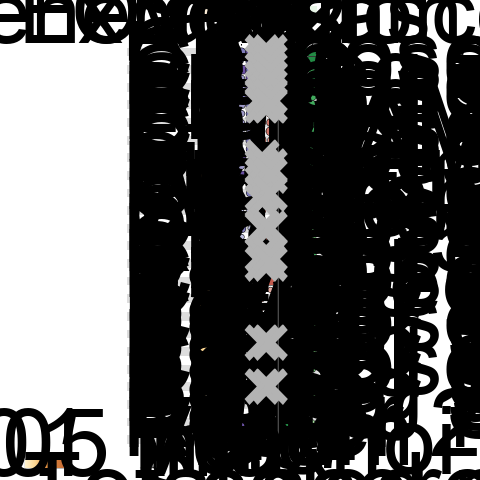

<rpy2.robjects.methods.RS4 object at 0x79361db21050> [25]
R classes: ('patchwork', 'plot_filler', 'ggplot2::ggplot', 'ggplot', 'ggplot2::gg', 'S7_object', 'gg')

In [35]:
categories = {
    "clustering": ["silhouette_score"],
    "marker": ["MECR_adj", "marker_f1"],
    "ficture": ["ficture_f1_score"],
    "z": ["Ovrlpy_stats_mean_integrity"],
}
ct = "vascular_celltypes"
ct_list = ["ECs", "SMCs", "Pericytes", "VLMCs", "BAMs"]
df_funky, raw = build_benchmark_table_vasc_subset(dfs, cell_types=ct_list, categories = categories, MECR_suffix=ct)
out_dir = str(main_dir / "metrics" / "aging" / f"benchmark_table_{ct}" / f"benchmark_table_{ct}")
df_funky.to_csv(Path(out_dir).parent/"df_funky.csv")
raw.to_csv(Path(out_dir).parent/"raw.csv")
%R -i df_funky -i out_dir -i metric_labels print(plot_benchmark_heatmap_vasc_celltypes(df_funky, out_dir, metric_labels, score_label = "Overall"))

In [30]:
categories = {
    "marker": ["MECR_adj", "marker_f1"],
    "ficture": ["ficture_f1_score"],
    "z": ["Ovrlpy_stats_mean_integrity"],
}
cell_types_dict = {
    "ecs": ["ECs"],
    "mural": ["SMCs", "Pericytes"],
    "neurons": ["Neurons", "Neurons-Glut", "Neurons-Gaba"],
    "oligo": ["Oligodendrocytes"],
}

ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


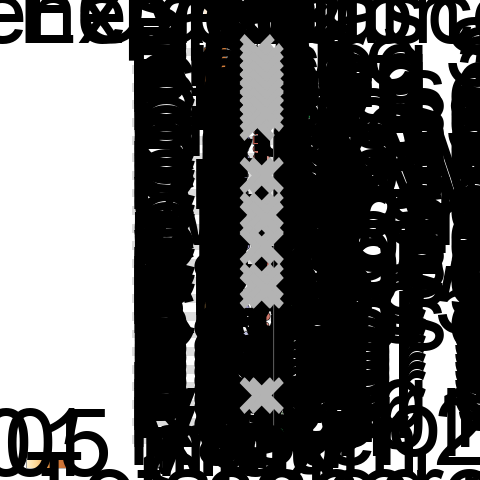

ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


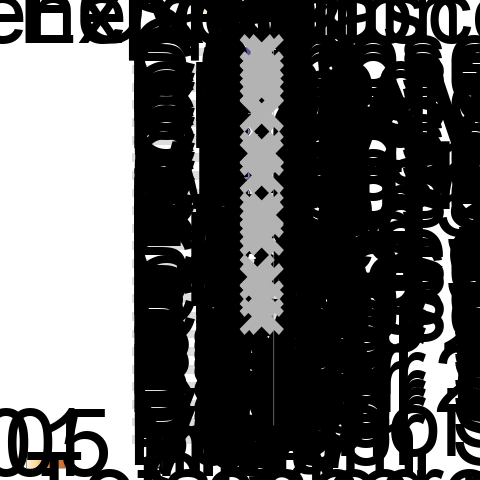

ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


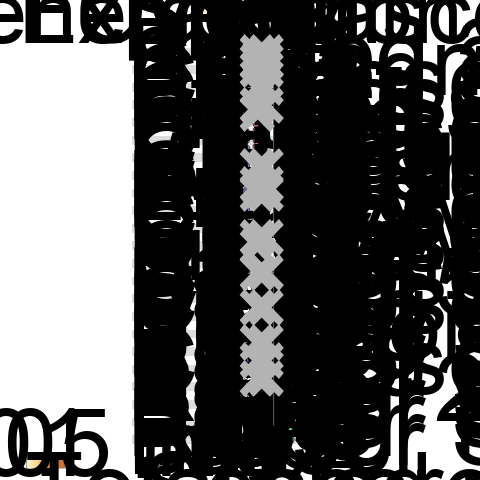

ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.
Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


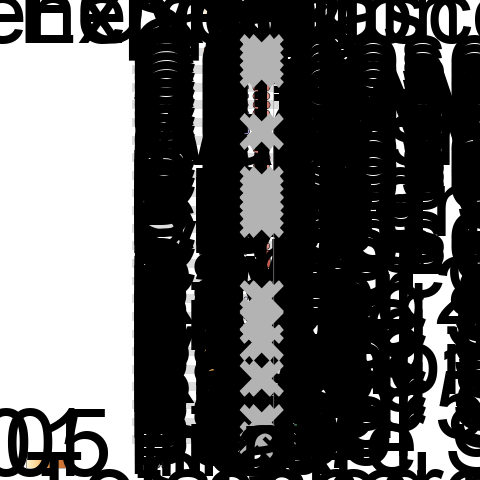

In [34]:
dfs = dfs_by['aging']
for ct, ct_list in cell_types_dict.items():
    df_funky, raw = build_benchmark_table_subsets(dfs, cell_types=ct_list, categories = categories, MECR_suffix=ct)
    out_dir = str(main_dir / "metrics" / "aging" / f"benchmark_table_{ct}" / f"benchmark_table_{ct}")
    df_funky.to_csv(Path(out_dir).parent/"df_funky.csv")
    raw.to_csv(Path(out_dir).parent/"raw.csv")
    %R -i df_funky -i out_dir -i metric_labels print(plot_benchmark_heatmap_subset_new(df_funky, out_dir, metric_labels, score_label = "Overall"))